<h1><center>Supervised ML Regression Competition</center></h1>


<img align="center" src="https://compraracciones.com/wp-content/uploads/2021/04/insurance.jpg" style="height:200px" style="width:100px"/>

<hr style="border:2px solid pink"> </hr>

You have been assigned the task of building a model that will predict the insurance cost

You'll find the data in the csv file `insurance`


- target col: "charges"


<hr style="border:2px solid pink"> </hr>


**Guidelines:** 


- train_test_split
    - random state = 42
    - test size = 0.3


- The one who gets the highest r2-score on test data wins


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
TEST_SIZE = 0.3

## 1. Initial Data Exploration

Let's start by loading our dataset and taking a first look at it.


In [2]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,7725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Checking for Missing Values

It's important to know if our data has any missing values. Let's check that next.


In [3]:
print(df.isna().sum())
print("\nDuplicated rows:", df.duplicated().sum())
df.info()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicated rows: 1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB



## 3. Descriptive Statistics

Now, let's move on to some descriptive statistics.

Understanding the distribution of our data is crucial. Let's calculate some descriptive statistics.


In [4]:
display(df.describe())
display(df.describe(include="object"))

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,15799.570247
std,14.049960,6.098187,1.205493,12559.984021
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,8106.480000
50%,39.000000,30.400000,1.000000,12403.585225
75%,51.000000,34.693750,2.000000,18948.612903
max,64.000000,53.130000,5.000000,64571.074480


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


## 4. Distribution Analysis

Visualizing the distributions of our features can provide valuable insights. Let's plot the distributions for 'age', 'bmi', and 'charges'.

### Task:
- Plot the histogram for 'age'
- Plot the histogram for 'bmi'
- Plot the histogram for 'charges'


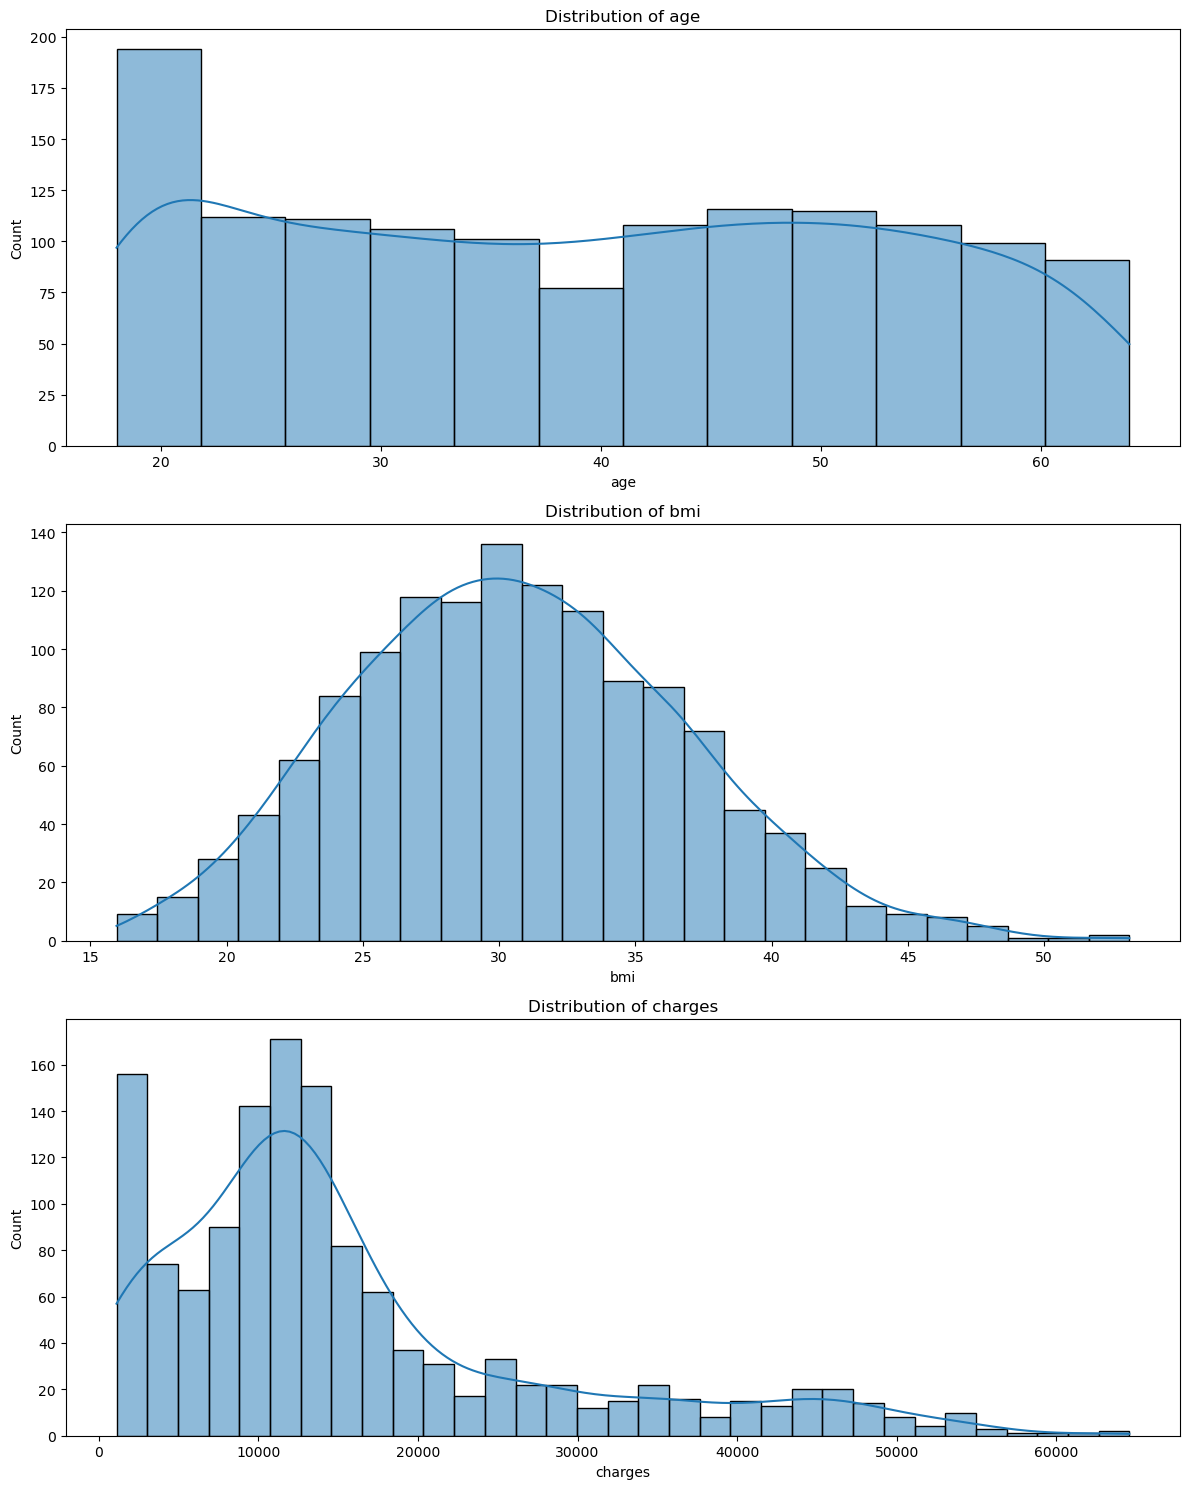

In [5]:
cols = ["age", "bmi", "charges"]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 5 * len(cols)))
for ax, col in zip(axes, cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

## 5. Relationship Between Variables

Let's explore the relationship between some of our features and the target variable 'charges'. We'll create scatter plots to visualize these relationships.

### Task:
- Create a scatter plot for 'age' vs 'charges'
- Create a scatter plot for 'bmi' vs 'charges'
- Create a scatter plot for 'children' vs 'charges'


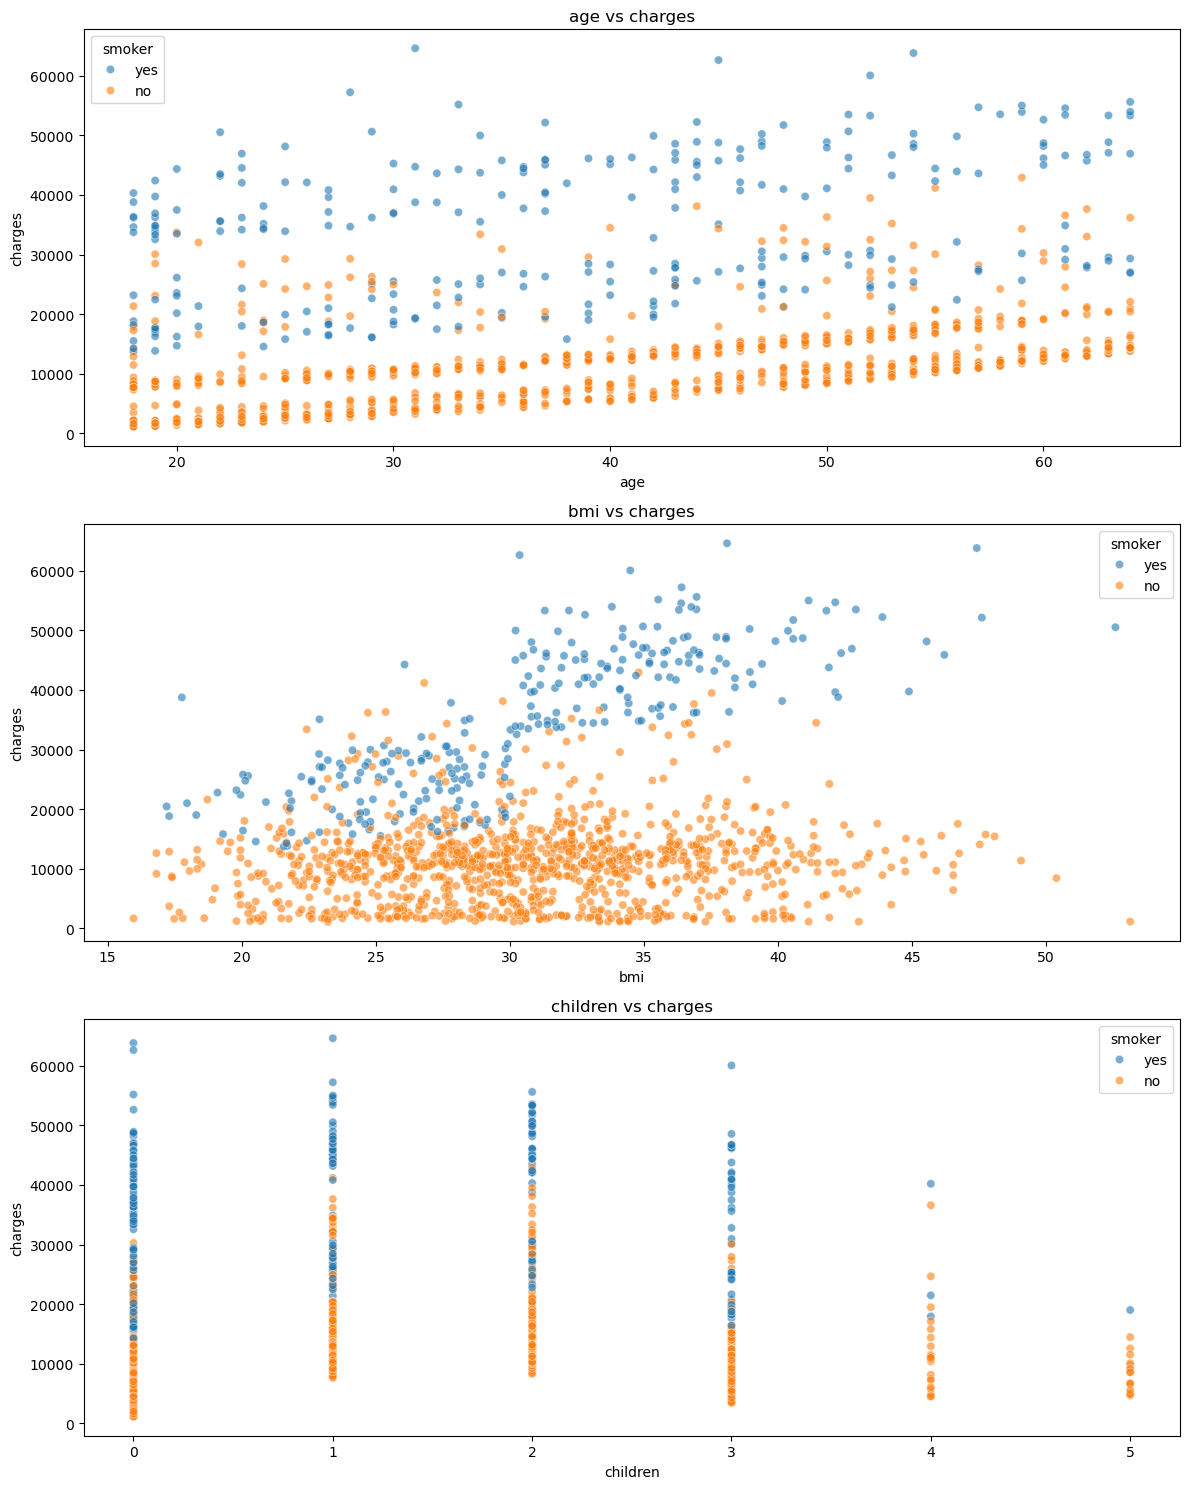

In [6]:
cols = ["age", "bmi", "children"]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 5 * len(cols)))
for ax, col in zip(axes, cols):
    sns.scatterplot(data=df, x=col, y="charges", hue="smoker", alpha=0.6, ax=ax)
    ax.set_title(f"{col} vs charges")
plt.tight_layout()
plt.show()

## 6. Categorical Analysis

Let's analyze the categorical features 'sex', 'smoker', and 'region' to see how they relate to 'charges'.

### Task:
- Plot the distribution of 'charges' for different 'sex'
- Plot the distribution of 'charges' for different 'smoker'
- Plot the distribution of 'charges' for different 'region'


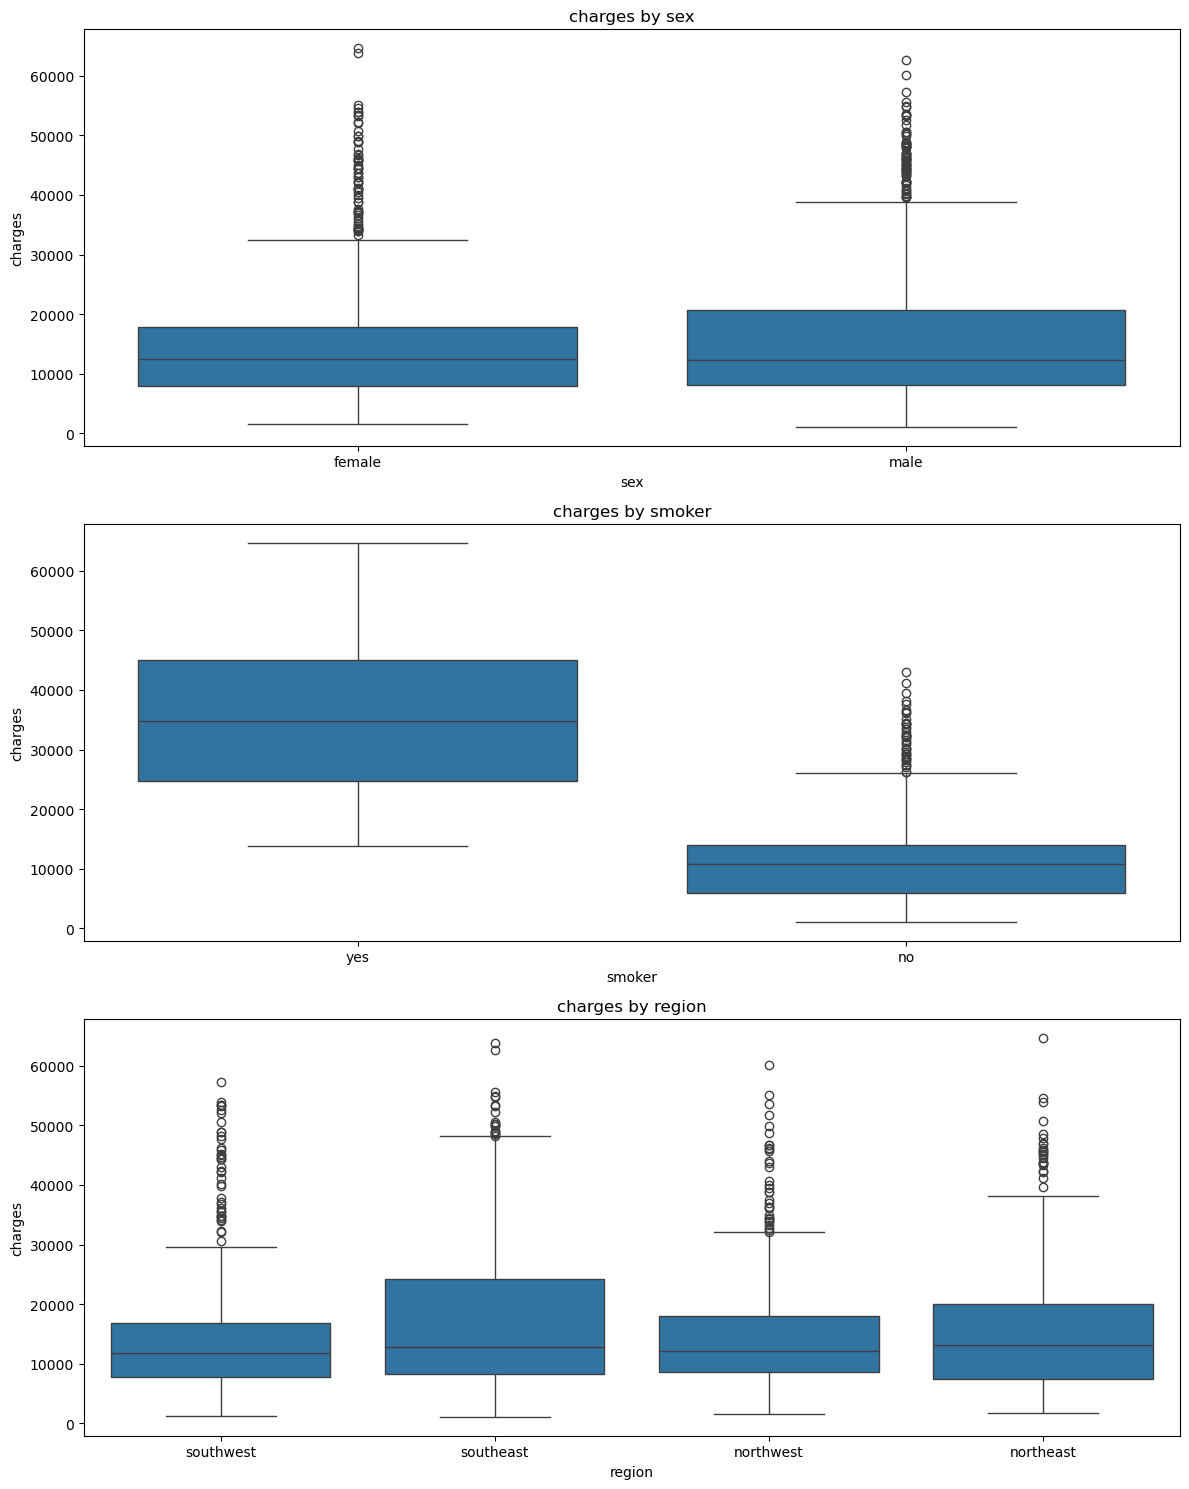

                mean        median  count
sex                                      
female  15080.152862  12477.530125    662
male    16504.088456  12376.462425    676 

                mean      median  count
smoker                                 
no      10960.584087  10764.1755   1064
yes     34590.377817  34725.8811    274 

                   mean        median  count
region                                      
northeast  15776.754887  13103.396425    324
northwest  15002.190759  12123.568800    325
southeast  17389.257591  12775.773350    364
southwest  14839.245070  11741.726000    325 



In [7]:
cols = ["sex", "smoker", "region"]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 5 * len(cols)))
for ax, col in zip(axes, cols):
    sns.boxplot(data=df, x=col, y="charges", ax=ax)
    ax.set_title(f"charges by {col}")
plt.tight_layout()
plt.show()

for col in ["sex", "smoker", "region"]:
    print(df.groupby(col)["charges"].agg(["mean", "median", "count"]), "\n")

## 7. Correlation Analysis

To understand how our numerical features relate to each other and to the target variable, let's calculate and visualize the correlation matrix.

### Task:
- Calculate the correlation matrix for the dataset
- Visualize the correlation matrix using a heatmap


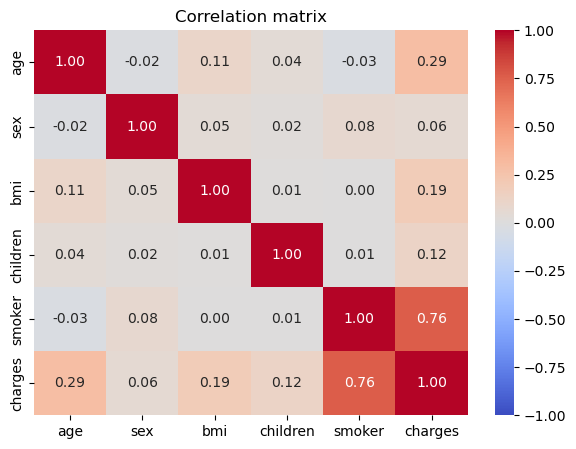

charges     1.000000
smoker      0.759492
age         0.291786
bmi         0.194897
children    0.120829
sex         0.056703
Name: charges, dtype: float64

In [8]:
# Encode the binary categoricals so they can be part of the correlation matrix
df_corr = df.assign(
    sex=(df["sex"] == "male").astype(int),
    smoker=(df["smoker"] == "yes").astype(int),
)
corr = df_corr.select_dtypes("number").corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

corr["charges"].sort_values(ascending=False)

There are no missing values. There is one duplicate row, but it stays in, so the train/test split is the same as for everyone else.

*charges* is skewed to the right: most people pay less than 15k, but a few go up to ~64k.

*smoker* is by far the strongest factor (correlation of **0.76**). Smokers pay about 3 times more on average. After that comes *age* (**0.29**) and then *bmi* (**0.19**).

In the *bmi vs charges* plot the smokers split into two groups at around bmi = 30. So it seems like smoking and being overweight together drive the costs up a lot. Lets keep that in mind for the feature engineering.

*sex* and *region* don't seem to make much of a difference.

# Modelling time!

## 1. Find the Naive Baseline

Before we build any models, let's establish a naive baseline. This will help us understand how well our models perform compared to a simple approach. In regression problems, the naive baseline is often the mean of the target variable.

### Task:
- Calculate the mean of the target variable 'charges'
- Explain why it's important to establish a naive baseline


In [9]:
# Split once here so every model (including the baseline) is evaluated on the same test set
X = df.drop(columns="charges")
y = df["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# The baseline must only "know" the training data: predict the training mean for everyone
baseline_value = y_train.mean()
print(f"Mean of charges (full data): {y.mean():.2f}")
print(f"Mean of charges (train):     {baseline_value:.2f}")

y_pred_baseline = np.full(len(y_test), baseline_value)

def evaluate(y_true, y_pred, name):
    """Return the regression metrics we track for every experiment."""
    return {
        "model": name,
        "r2": r2_score(y_true, y_pred),
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

results = [evaluate(y_test, y_pred_baseline, "Naive baseline (mean)")]
pd.DataFrame(results)

Mean of charges (full data): 15799.57
Mean of charges (train):     15891.98


,model,r2,mae,rmse
0,Naive baseline (mean),-0.000602,9446.147467,12541.030898


Why a baseline? It shows the score we get without any real model, just by always guessing the average charge. Every model has to beat this, otherwise it is useless.

The R² is around 0 (slightly below 0 here, because the train mean is not exactly the test mean). The baseline RMSE (**~12 541**) is the number in dollars that every model is compared against.

## 2. Initial Modelling Without GridSearch or Pipeline

Let's build a simple linear regression model without any feature engineering, grid search, or pipeline. This will serve as our initial baseline for comparison.

### Task:
- Split the data into training and test sets, using the guidelines at the top (`test_size=0.3`, `random_state=42`)
- Encode the text columns `sex`, `smoker` and `region` first: a model only accepts numbers. `pd.get_dummies(..., drop_first=True)` is enough here
- Train a simple linear regression model
- Evaluate its performance using regression metrics
- Write it down as a markdown below so you can keep track. This is a scientific experiment


In [10]:
# One-hot encode categoricals; drop_first avoids the dummy-variable trap for linear regression
X_enc = pd.get_dummies(X, drop_first=True, dtype=int)
X_train_enc, X_test_enc, y_train, y_test = train_test_split(X_enc, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

lr = LinearRegression()
lr.fit(X_train_enc, y_train)
y_pred_lr = lr.predict(X_test_enc)

results.append(evaluate(y_test, y_pred_lr, "Linear regression (raw features)"))
pd.DataFrame(results)

,model,r2,mae,rmse
0,Naive baseline (mean),-0.000602,9446.147467,12541.030898
1,Linear regression (raw features),0.726344,4996.264727,6558.510613


Keeping track of the results:

| # | Model | Features | Test R² | MAE | RMSE |
|---|---|---|---|---|---|
| 0 | Baseline (train mean) | – | -0.001 | 9 446 | 12 541 |
| 1 | LinearRegression | raw, one-hot encoded | 0.726 | 4 996 | 6 559 |

The simple linear regression already explains about **73%** of the variance. Big step up from the baseline.

## 3. Feature Engineering

Now, let's brainstorm and create some new features to see if we can improve the model's performance.

### Questions:
1. Should we create an interaction feature between 'bmi' and 'children'? 
2. Should we create age groups to see if the model improves by categorizing age?
3. Should we create a high-risk indicator based on 'smoker' and 'bmi'?

- Remember nothing is set in stone, this is your experiment, your hypothesis. You may not need to, but its important to explore these questions

### Task:
- Create new features based on the questions above
- Explain the rationale behind each feature



Answering the questions from above:

1. **bmi × children** (*bmi_children*): Maybe bigger families with a high bmi cost more? *children* had almost no relation to *charges* in the plots, so probably not much will come out of it. But it is cheap to try.
2. **age groups** (*age_group*): Charges go up with age, and insurances usually price by age groups. Putting ages into groups lets the linear model handle that better. The groups are fixed by hand, so nothing is learned from the test data.
3. **high-risk indicator** (*high_risk* = smoker AND bmi ≥ 30): This is the pattern from the EDA where the smokers split into two groups. A linear model can't figure out this AND on its own, so this one should help the most.
4. **Extra**: *age_sq* (charges seem to grow faster at higher ages) and *smoker_bmi* (bmi seems to matter mostly for smokers).

In [11]:
def add_features(data):
    """Row-wise feature engineering (uses no statistics from other rows, so it cannot leak test data)."""
    out = data.copy()
    is_smoker = (out["smoker"] == "yes").astype(int)
    is_obese = (out["bmi"] >= 30).astype(int)

    # Q1: interaction between bmi and children
    out["bmi_children"] = out["bmi"] * out["children"]
    # Q2: age groups (bins chosen up front, not learned from the data)
    out["age_group"] = pd.cut(out["age"], bins=[17, 30, 45, 60, 100], labels=["18-30", "31-45", "46-60", "60+"]).astype(str)
    # Q3: high-risk indicator = smoker AND obese
    out["high_risk"] = is_smoker * is_obese
    # Extra: non-linear age effect and smoker x bmi interaction
    out["age_sq"] = out["age"] ** 2
    out["smoker_bmi"] = is_smoker * out["bmi"]
    return out

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
X_train_fe.head()

,age,sex,bmi,children,smoker,region,bmi_children,age_group,high_risk,age_sq,smoker_bmi
332,61,female,31.160,0,no,northwest,0.00,60+,0,3721,0.000
355,46,male,27.600,0,no,southwest,0.00,46-60,0,2116,0.000
138,54,female,31.900,3,no,southeast,95.70,46-60,0,2916,0.000
381,55,male,30.685,0,yes,northeast,0.00,46-60,1,3025,30.685
292,25,male,45.540,2,yes,southeast,91.08,18-30,1,625,45.540


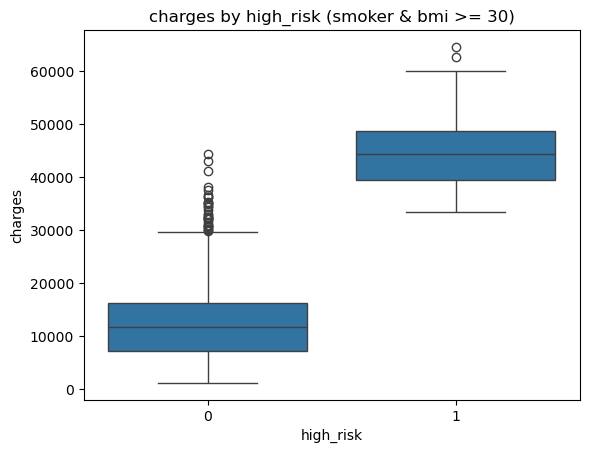

In [12]:
# Sanity check: does the high-risk flag separate the charges?
sns.boxplot(x=X_train_fe["high_risk"], y=y_train)
plt.title("charges by high_risk (smoker & bmi >= 30)")
plt.show()

## 4. Modelling with Feature Engineering

Now that we have new features, let's see if they improve our model's performance.
Did it improve the performance? Yes? No? Why

### Task:
- Split the data into training and test sets
- Train a linear regression model with the new features
- Evaluate its performance using regression metrics


In [13]:
X_fe_enc = pd.get_dummies(add_features(X), drop_first=True, dtype=int)
X_train_fe_enc, X_test_fe_enc, y_train, y_test = train_test_split(X_fe_enc, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

lr_fe = LinearRegression()
lr_fe.fit(X_train_fe_enc, y_train)
y_pred_lr_fe = lr_fe.predict(X_test_fe_enc)

results.append(evaluate(y_test, y_pred_lr_fe, "Linear regression (engineered features)"))
pd.DataFrame(results)

,model,r2,mae,rmse
0,Naive baseline (mean),-0.000602,9446.147467,12541.030898
1,Linear regression (raw features),0.726344,4996.264727,6558.510613
2,Linear regression (engineered features),0.821465,3747.194283,5297.425701


Did it improve? Yes! R² went from **0.726** to **0.821** and RMSE from ~6 559 to ~5 297.

Most of that comes from *high_risk* and *smoker_bmi*. They tell the model about the smoker + overweight combination, which it can't figure out from the raw columns. *bmi_children* doesn't really help, as expected.

## 5. Modelling with Pipeline and Grid Search

Now, let's see how using pipelines can simplify our workflow and prevent data leakage. We'll also use GridSearchCV to find the best hyperparameters.

### Task:
- Create a pipeline that starts from the raw columns: a `ColumnTransformer` that one-hot encodes the text columns and scales the numeric ones, followed by a `Ridge` regression
- Plain `LinearRegression` has no hyperparameter worth tuning; `Ridge` has `alpha`, the strength of its regularisation. Define a grid of `alpha` values (for example from 0.01 to 100)
- Use `GridSearchCV` on the training set to find the best `alpha`, then evaluate the best model on the test set once


In [14]:
numeric_features = ["age", "bmi", "children", "bmi_children", "high_risk", "age_sq", "smoker_bmi"]
categorical_features = ["sex", "smoker", "region", "age_group"]

def make_preprocessor():
    # Scaling/encoding is fitted inside each CV fold -> no information from the validation fold leaks in
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
    ])

linear_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", Ridge()),
])

# Separate sub-grids so alpha is only searched for the models that have it
linear_grid = [
    {"model": [LinearRegression()]},
    {"model": [Ridge()], "model__alpha": [0.01, 0.1, 1, 10, 100]},
    {"model": [Lasso(max_iter=50_000)], "model__alpha": [0.1, 1, 10, 100]},
]

linear_search = GridSearchCV(linear_pipe, linear_grid, cv=5, scoring="r2", n_jobs=-1)
linear_search.fit(X_train_fe, y_train)

print("Best params:", linear_search.best_params_)
print(f"Best CV r2:  {linear_search.best_score_:.4f}")

y_pred_linear_gs = linear_search.predict(X_test_fe)
results.append(evaluate(y_test, y_pred_linear_gs, "Pipeline + GridSearch (linear)"))
pd.DataFrame(results)

Best params: {'model': Lasso(max_iter=50000), 'model__alpha': 100}
Best CV r2:  0.8074


,model,r2,mae,rmse
0,Naive baseline (mean),-0.000602,9446.147467,12541.030898
1,Linear regression (raw features),0.726344,4996.264727,6558.510613
2,Linear regression (engineered features),0.821465,3747.194283,5297.425701
3,Pipeline + GridSearch (linear),0.824217,3729.457181,5256.433960


The best linear model is a Lasso with a strong regularization (alpha = 100). CV R² is **0.807** and test R² **0.824**. So only a tiny bit better than the plain linear regression.

Scaling and regularization don't change much here. The real benefit of the pipeline is that the scaling and encoding happen inside each CV fold, so no info from the validation data leaks into training.

## 6. Trying Another Model with Pipeline

Let's try a model that can capture non-linear patterns, such as the smoker and BMI interaction you may have spotted.

### Task:
- Create a pipeline with the same preprocessing and a `KNeighborsRegressor` (tune `n_neighbors`) or a `DecisionTreeRegressor` (tune `max_depth` and `min_samples_leaf`)
- Define a parameter grid for grid search
- Use GridSearchCV to find the best parameters and evaluate the model

Tomorrow's lesson introduces ensembles. Come back afterwards and try `RandomForestRegressor` and `GradientBoostingRegressor` in the same pipeline: they usually win this challenge.

In [15]:
gbr_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE)),
])

gbr_grid = {
    "model__n_estimators": [100, 200, 400],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_leaf": [1, 5, 10],
}

gbr_search = GridSearchCV(gbr_pipe, gbr_grid, cv=5, scoring="r2", n_jobs=-1)
gbr_search.fit(X_train_fe, y_train)

print("Best params:", gbr_search.best_params_)
print(f"Best CV r2:  {gbr_search.best_score_:.4f}")

y_pred_gbr = gbr_search.predict(X_test_fe)
results.append(evaluate(y_test, y_pred_gbr, "Pipeline + GridSearch (GradientBoosting)"))
pd.DataFrame(results)

Best params: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best CV r2:  0.8567


,model,r2,mae,rmse
0,Naive baseline (mean),-0.000602,9446.147467,12541.030898
1,Linear regression (raw features),0.726344,4996.264727,6558.510613
2,Linear regression (engineered features),0.821465,3747.194283,5297.425701
3,Pipeline + GridSearch (linear),0.824217,3729.457181,5256.433960
4,Pipeline + GridSearch (GradientBoosting),0.882395,2476.218429,4299.483236


Gradient Boosting is clearly better: CV R² **0.857**, test R² **0.882** and RMSE ~4 299.

Makes sense, since trees can find thresholds like bmi ≥ 30 or age groups by themselves. A linear model only gets those if we build them by hand.

## 7. GridSearch with Several Models

Finally, let's compare several models using GridSearchCV to find the best one.

### Task:
- Define multiple models and their parameter grids
- Use GridSearchCV to find the best model and parameters

*Hint:* `GridSearchCV` accepts a list of grids, and the model step itself can be one of the parameters:

```python
param_grid = [
    {"model": [Ridge()], "model__alpha": [0.1, 1, 10]},
    {"model": [DecisionTreeRegressor(random_state=42)], "model__max_depth": [3, 5, 8]},
]
```

In [16]:
multi_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", Ridge()),
])

multi_grid = [
    {"model": [Ridge()], "model__alpha": [0.1, 1, 10]},
    {"model": [RandomForestRegressor(random_state=RANDOM_STATE)],
     "model__n_estimators": [200, 400],
     "model__max_depth": [4, 6, None],
     "model__min_samples_leaf": [1, 5, 10]},
    {"model": [GradientBoostingRegressor(random_state=RANDOM_STATE)],
     "model__n_estimators": [100, 200],
     "model__learning_rate": [0.05, 0.1],
     "model__max_depth": [2, 3]},
]

multi_search = GridSearchCV(multi_pipe, multi_grid, cv=5, scoring="r2", n_jobs=-1)
multi_search.fit(X_train_fe, y_train)

# Best CV score per model family
cv_results = pd.DataFrame(multi_search.cv_results_)
cv_results["model_name"] = cv_results["param_model"].apply(lambda m: type(m).__name__)
display(cv_results.groupby("model_name")["mean_test_score"].max().sort_values(ascending=False))

print("Best params:", multi_search.best_params_)
print(f"Best CV r2:  {multi_search.best_score_:.4f}")

y_pred_multi = multi_search.predict(X_test_fe)
results.append(evaluate(y_test, y_pred_multi, f"Multi-model GridSearch ({type(multi_search.best_estimator_['model']).__name__})"))
pd.DataFrame(results).sort_values("r2", ascending=False)

model_name
GradientBoostingRegressor    0.856660
RandomForestRegressor        0.846791
Ridge                        0.804885
Name: mean_test_score, dtype: float64

Best params: {'model': GradientBoostingRegressor(random_state=42), 'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}
Best CV r2:  0.8567


,model,r2,mae,rmse
4,Pipeline + GridSearch (GradientBoosting),0.882395,2476.218429,4299.483236
5,Multi-model GridSearch (GradientBoostingRegres...,0.882395,2476.218429,4299.483236
3,Pipeline + GridSearch (linear),0.824217,3729.457181,5256.433960
2,Linear regression (engineered features),0.821465,3747.194283,5297.425701
1,Linear regression (raw features),0.726344,4996.264727,6558.510613
0,Naive baseline (mean),-0.000602,9446.147467,12541.030898


Comparing all models, Gradient Boosting wins on cross-validation (**0.857**), then Random Forest (**0.847**) and Ridge (**0.805**). So Gradient Boosting is the final model.

# Machine Learning: Master Challenge

## 8. Calculating Potential Cost or Loss

### Challenge:
Now that you've built and optimized your models, it's time for the final challenge! Your task is to minimize the Root Mean Squared Error (RMSE) of your model's predictions and calculate the potential financial impact of your model's errors.

### Task:
1. Calculate the RMSE of your final model's predictions.
2. Break down the errors into underestimation and overestimation.
3. Calculate the total potential cost or loss to the company.
4. Compete with your classmates to see who can achieve the lowest RMSE and financial impact!

### Explanation:
The RMSE provides an estimate of the average error in your model's predictions. We will also analyze the errors by categorizing them into underestimations and overestimations to understand their financial impact.

#### Steps to Calculate Underestimation and Overestimation Errors:

1. **Calculate RMSE**:
   - Use the `mean_squared_error` function from `sklearn.metrics` and pass your actual values (`y_test`) and predicted values (`y_pred_final`) to it.
   - Take the square root of the result to get the RMSE, or use `root_mean_squared_error` directly.
   
2. **Calculate Underestimation Error**:
   - Identify the instances where the actual charges (`y_test`) are greater than the predicted charges (`y_pred_final`).
   - For these instances, calculate the difference between the actual and predicted charges.
   - Sum these differences to get the total underestimation error.

3. **Calculate Overestimation Error**:
   - Identify the instances where the actual charges (`y_test`) are less than the predicted charges (`y_pred_final`).
   - For these instances, calculate the difference between the predicted and actual charges.
   - Sum these differences to get the total overestimation error.

4. **Calculate Total Potential Cost or Loss**:
   - Add the total underestimation error and the total overestimation error to get the total potential cost or loss. This is the sum of the absolute errors, so it is the MAE multiplied by the number of test rows.

### Let's see who can build the best model!

#### Detailed Instructions:

1. **Calculate RMSE**:
   - Use `mean_squared_error` with `y_test` and `y_pred_final`.
   - Use `np.sqrt` to take the square root of the result.

2. **Calculate Underestimation Error**:
   - Use a boolean condition to filter `y_test` values that are greater than `y_pred_final`.
   - Subtract the predicted values from the actual values for these instances.
   - Sum these differences.

3. **Calculate Overestimation Error**:
   - Use a boolean condition to filter `y_test` values that are less than `y_pred_final`.
   - Subtract the actual values from the predicted values for these instances.
   - Sum these differences.

4. **Calculate Total Potential Cost or Loss**:
   - Add the results of the underestimation error and overestimation error to get the total potential cost or loss.

### Example Walkthrough:

1. **Calculate RMSE**:
   - `rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))`
   - This gives you the average prediction error in dollars.

2. **Calculate Underestimation Error**:
   - `underestimation_error = np.sum(y_test[y_test > y_pred_final] - y_pred_final[y_test > y_pred_final])`
   - This gives you the total amount by which the model undercharged.

3. **Calculate Overestimation Error**:
   - `overestimation_error = np.sum(y_pred_final[y_test < y_pred_final] - y_test[y_test < y_pred_final])`
   - This gives you the total amount by which the model overcharged.

4. **Calculate Total Potential Cost or Loss**:
   - `total_potential_loss = underestimation_error + overestimation_error`
   - This gives you the total financial impact of the model's errors.

### Leaderboard:
Post your RMSE score and total potential cost or loss on the class leaderboard. The student with the lowest RMSE and total potential cost or loss wins bragging rights

### Post Your Results 

- Name
- Model Type
- RMSE
- Underestimation Error
- Overestimation Error
- Total Potential Cost/Loss

In [17]:
# Pick the final model by cross-validated score (choosing by test score would be overfitting to the test set)
candidates = {
    "Linear (GridSearch)": linear_search,
    "GradientBoosting (GridSearch)": gbr_search,
    "Multi-model (GridSearch)": multi_search,
}
final_name, final_search = max(candidates.items(), key=lambda kv: kv[1].best_score_)
y_pred_final = final_search.predict(X_test_fe)

y_true = y_test.values
rmse = np.sqrt(mean_squared_error(y_true, y_pred_final))

under_mask = y_true > y_pred_final
over_mask = y_true < y_pred_final
underestimation_error = np.sum(y_true[under_mask] - y_pred_final[under_mask])
overestimation_error = np.sum(y_pred_final[over_mask] - y_true[over_mask])
total_potential_loss = underestimation_error + overestimation_error

print(f"Final model:                {final_name}")
print(f"R2 (test):                  {r2_score(y_true, y_pred_final):.4f}")
print(f"RMSE:                       {rmse:,.2f}")
print(f"Underestimation error:      {underestimation_error:,.2f}  ({under_mask.sum()} customers undercharged)")
print(f"Overestimation error:       {overestimation_error:,.2f}  ({over_mask.sum()} customers overcharged)")
print(f"Total potential cost/loss:  {total_potential_loss:,.2f}")

Final model:                GradientBoosting (GridSearch)
R2 (test):                  0.8824
RMSE:                       4,299.48
Underestimation error:      439,403.53  (58 customers undercharged)
Overestimation error:       556,036.28  (344 customers overcharged)
Total potential cost/loss:  995,439.81


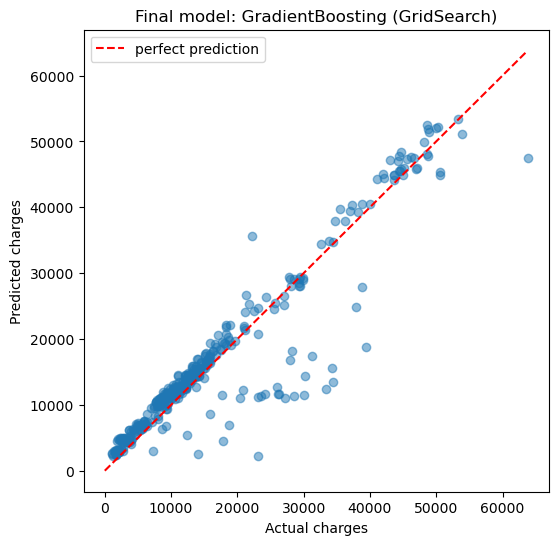

In [18]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_final, alpha=0.5)
lims = [0, max(y_test.max(), y_pred_final.max())]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("Actual charges")
plt.ylabel("Predicted charges")
plt.title(f"Final model: {final_name}")
plt.legend()
plt.show()

### Post Your Results

- **Name:** Tamim Wahage
- **Model Type:** GradientBoostingRegressor (pipeline + GridSearchCV, with the new features)
- **Test R²:** 0.8824
- **RMSE:** 4 299.48
- **Underestimation Error:** 439 403.53 (58 customers)
- **Overestimation Error:** 556 036.28 (344 customers)
- **Total Potential Cost/Loss:** 995 439.81

The model overcharges most customers by a small amount and undercharges a few by a lot. The big underestimates are the dots far above the red line in the plot. Most of them are non-smokers with unusually high charges, which the features can't explain.

## Conclusion

Congratulations! You've completed the lab. Here's a summary of what we've covered:
1. Established a naive baseline using the mean of the target variable.
2. Built an initial linear regression model without any feature engineering or optimization.
3. Performed feature engineering to create new, potentially useful features.
4. Used pipelines and GridSearchCV to optimize the model.
5. Evaluated the final model's performance using RMSE to understand its business impact.

By following these steps, you now have a robust understanding of how to approach a regression problem, from initial exploration to model optimization and business impact assessment. Great job!
